# 2. Player archetypes in the Liga Femenina Endesa
This notebook starts from the CSV files created in `01_dados.ipynb` (no web requests).
Plan: finish the data (missing heights, positions), build per-100-possession features,
then find archetypes (Archetypal Analysis, as in "Scouting Anyone") and compare them with K-Means.

In [1]:
import pandas as pd
import numpy as np

In [10]:
players = {
    2025: pd.read_csv("data/season_2025_26.csv", dtype={"player_id": str}),
    2026: pd.read_csv("data/season_2026_27.csv", dtype={"player_id": str}),
}
teams = {
    2025: pd.read_csv("data/teams_2025_26.csv"),
    2026: pd.read_csv("data/teams_2026_27.csv"),
}

for season in [2025, 2026]:
    print(season, "players:", players[season].shape, "| teams:", teams[season].shape)

2025 players: (248, 32) | teams: (16, 27)
2026 players: (192, 31) | teams: (16, 27)


In [11]:
min_minutes = {2025: 300, 2026: 70}     # ~10 minutes per game, as in the paper

for season in [2025, 2026]:
    df = players[season]
    missing = df[(df["min"] >= min_minutes[season]) & df["height"].isna()]
    print(f"\n{season}: {len(missing)} players without height")
    print(missing[["player_id", "player", "team", "min"]].to_string(index=False))


2025: 5 players without height
player_id                            player                              team        min
  2100039          CONTELL SANCHIS, CLAUDIA                 SPAR GRAN CANARIA 330.966667
  2451428             GEORGE, ANISHA BRIANA                 SPAR GRAN CANARIA 448.766667
  2823534 MERCERON, AXELLE CECILE ELISABETH                 SPAR GRAN CANARIA 764.166667
  2912506          CARRERA QUINTANA, RAQUEL                     VALENCIA B.C. 437.050000
  2825497         GARRICK, MADELEINE CLAIRE INGENIERÍA AMBIENTAL CAB ESTEPONA 403.000000

2026: 5 players without height
player_id                  player                     team        min
  2880590      SONTAG, LINA MERLE              CADI LA SEU 123.516667
  2894216 MCSPADDEN, LARA GWENETH INVERSUS GERNIKA BIZKAIA 113.400000
  1813104 SUAREZ RODRIGUEZ, MARTA            VALENCIA B.C.  92.683333
  2378075 HERNANDEZ LOPEZ, ISABEL            VALENCIA B.C.  76.316667
  2893730    YURKEVICHUS, TETIANA  DURÁN MAQUINARIA 

In [12]:
manual_heights = pd.DataFrame([
    ("2100039", "CONTELL SANCHIS, CLAUDIA",   177, "https://www.fiba.basketball/en/players/271705-claudia-contell"),
    ("2451428", "GEORGE, ANISHA BRIANA",      188, "https://www.fiba.basketball/en/players/210937-anisha-briana-george"),
    ("2823534", "MERCERON, AXELLE",           189, "https://www.fiba.basketball/en/players/297847-axelle-merceron"),
    ("2912506", "CARRERA QUINTANA, RAQUEL",   190, "https://fiba.basketball/en/players/225137-raquel-carrera-quintana"),
    ("2825497", "GARRICK, MADELEINE",         178, "https://www.fiba.basketball/en/players/189500-madeleine-garrick"),
    ("2880590", "SONTAG, LINA MERLE",         191, "https://www.fiba.basketball/en/players/251173-lina-sontag"),
    ("2894216", "MCSPADDEN, LARA GWENETH",    194, "https://kirolakeitb.eus/en/basketball/teams/gernika-saski/2026/08/21/australian-pivot-lara-mcspadden-to-play-at-inversus-gernika/"),
    ("1813104", "SUAREZ RODRIGUEZ, MARTA",    187, "https://www.fiba.basketball/en/players/251418-marta-suarez-rodriguez"),
    ("2378075", "HERNANDEZ LOPEZ, ISABEL",    173, "https://www.fiba.basketball/en/players/395391-isabel-hernandez"),
    ("2893730", "YURKEVICHUS, TETIANA",       185, "https://www.fiba.basketball/en/players/183614-tetiana-yurkevichus"),
], columns=["player_id", "player", "height", "source"])

manual_heights.to_csv("data/manual_heights.csv", index=False)   # the record stays in the data folder

lookup = manual_heights.set_index("player_id")["height"]
for season in [2025, 2026]:
    df = players[season]
    if "height_feb" not in df.columns:            # keep the original FEB height once, never touch it again
        df["height_feb"] = df["height"]
    df["height"] = df["height_feb"].fillna(df["player_id"].map(lookup))
    df["height_source"] = np.where(df["height_feb"].notna(), "FEB",
                          np.where(df["height"].notna(), "manual", None))
    print(season, df["height_source"].value_counts(dropna=False).to_dict())

2025 {'FEB': 180, nan: 63, 'manual': 5}
2026 {'FEB': 166, nan: 20, 'manual': 6}


**Heights:** every player above the minutes filter now has a height. The column `height_source` says where it comes from
("FEB", or "manual" from the official sources in `data/manual_heights.csv`). Players without height all have very few minutes and are filtered out later.

In [14]:
for season in [2025, 2026]:
    print(season, players[season]["position"].value_counts(dropna=False).to_dict())

2025 {nan: 83, 'Base': 41, 'Alero': 34, 'Pívot': 30, 'Escolta': 27, 'A-Pivot': 26, 'A-Pívot': 3, 'A-Piv': 2, 'Esc': 1, 'A-piv': 1}
2026 {'PÍVOT': 36, nan: 35, 'ESCOLTA': 33, 'BASE': 31, 'ALERO': 30, 'A-PÍVOT': 24, 'Base': 1, 'Alero': 1, 'A-PIVOT': 1}


In [15]:
import unicodedata

def clean_position(p):
    """'Pívot', 'PÍVOT', 'A-Piv', 'Esc' ... -> one English label (PG, SG, SF, PF, C)."""
    if pd.isna(p):
        return None
    p = unicodedata.normalize("NFKD", str(p)).encode("ascii", "ignore").decode()   # remove accents: Í -> I
    p = p.upper().strip()                                                          # same case, no spaces
    spanish = {"BASE": "PG",
               "ESCOLTA": "SG", "ESC": "SG",
               "ALERO": "SF",
               "A-PIVOT": "PF", "A-PIV": "PF",
               "PIVOT": "C"}
    return spanish.get(p, p)          # if a value is not in the dictionary, keep it so we can see it

for season in [2025, 2026]:
    players[season]["position"] = players[season]["position"].apply(clean_position)
    print(season, players[season]["position"].value_counts(dropna=False).to_dict())

2025 {nan: 83, 'PG': 41, 'SF': 34, 'PF': 32, 'C': 30, 'SG': 28}
2026 {'C': 36, nan: 35, 'SG': 33, 'PG': 32, 'SF': 31, 'PF': 25}


### Minutes filter
As in the paper, players need enough minutes for their numbers to mean something:
300 minutes in the full 2025/26 season (~10 per game), 70 in the first 7 rounds of 2026/27 (the same rate).

In [16]:
for season in [2025, 2026]:
    df = players[season]
    df["in_sample"] = df["min"] >= min_minutes[season]          # True / False, one per player
    sample = df[df["in_sample"]]
    print(f"{season}: {len(sample)} of {len(df)} players in the sample | "
          f"no height: {sample['height'].isna().sum()} | no position: {sample['position'].isna().sum()}")

2025: 142 of 248 players in the sample | no height: 0 | no position: 6
2026: 142 of 192 players in the sample | no height: 0 | no position: 9


In [17]:
other = {2025: 2026, 2026: 2025}

for season in [2025, 2026]:                                   # 1. keep the original FEB position once
    df = players[season]
    if "position_feb" not in df.columns:
        df["position_feb"] = df["position"]

positions_by_id = {season: players[season].dropna(subset=["position_feb"])
                                          .drop_duplicates("player_id")
                                          .set_index("player_id")["position_feb"]
                   for season in [2025, 2026]}

for season in [2025, 2026]:                                   # 2. fill the gaps with the other season
    df = players[season]
    df["position"] = df["position_feb"].fillna(df["player_id"].map(positions_by_id[other[season]]))
    still_missing = df[df["in_sample"] & df["position"].isna()]
    print(f"\n{season}: {len(still_missing)} players in the sample still without position")
    print(still_missing[["player", "team", "height", "min"]].to_string(index=False))


2025: 4 players in the sample still without position
                           player                              team  height        min
         CONTELL SANCHIS, CLAUDIA                 SPAR GRAN CANARIA   177.0 330.966667
            GEORGE, ANISHA BRIANA                 SPAR GRAN CANARIA   188.0 448.766667
MERCERON, AXELLE CECILE ELISABETH                 SPAR GRAN CANARIA   189.0 764.166667
        GARRICK, MADELEINE CLAIRE INGENIERÍA AMBIENTAL CAB ESTEPONA   178.0 403.000000

2026: 5 players in the sample still without position
                  player                    team  height        min
      SONTAG, LINA MERLE             CADI LA SEU   191.0 123.516667
 SUAREZ RODRIGUEZ, MARTA           VALENCIA B.C.   187.0  92.683333
 HERNANDEZ LOPEZ, ISABEL           VALENCIA B.C.   173.0  76.316667
    YURKEVICHUS, TETIANA DURÁN MAQUINARIA ENSINO   185.0  79.366667
DIALLO DIENG, UMO DIALLO    IMPULSO 360 ESTEPONA   193.0 138.950000


**Positions:** missing positions were filled with the other season (same player id). 9 players in the samples
(4 in 2025/26, 5 in 2026/27) still have no position. Position is not a model input, so they stay in the model
and appear as "no position" only in the final comparison with the archetypes.

In [18]:
for season in [2025, 2026]:
    players[season].to_csv(f"data/players_ready_{season}.csv", index=False)
print("Saved")

Saved


## 3. Features
Every feature is a rate, so players from fast and slow teams, with many or few minutes, can be compared.
Most rates need the team's totals and the **opponents'** totals while the player is on court,
so we first build that context for every team.

In [19]:
players = {s: pd.read_csv(f"data/players_ready_{s}.csv", dtype={"player_id": str}) for s in [2025, 2026]}
teams   = {2025: pd.read_csv("data/teams_2025_26.csv"),     2026: pd.read_csv("data/teams_2026_27.csv")}
box     = {2025: pd.read_csv("data/boxscores_2025_26.csv"), 2026: pd.read_csv("data/boxscores_2026_27.csv")}

for s in [2025, 2026]:
    print(s, players[s].shape, teams[s].shape, box[s].shape)

2025 (248, 36) (16, 27) (4659, 30)
2026 (192, 35) (16, 27) (1124, 30)


In [20]:
opp_cols = ["fg_att", "fg2_att", "oreb", "dreb", "tov", "ft_att"]
team_cols = ["team", "min", "poss", "fg_made", "fg_att", "oreb", "dreb", "tov", "ft_att"]

context = {}
for s in [2025, 2026]:
    # What opponents did against each team: add up every box score row where that team was the opponent
    opp = box[s].groupby("opponent")[opp_cols].sum().add_prefix("opp_")
    opp["opp_poss"] = opp["opp_fg_att"] - opp["opp_oreb"] + opp["opp_tov"] + 0.44 * opp["opp_ft_att"]

    # The team's own official totals, with a prefix so the names never clash with the player's
    own = teams[s][team_cols].set_index("team").add_prefix("team_")

    context[s] = own.join(opp)
    print(s, context[s].shape)

context[2025][["team_poss", "opp_poss"]].assign(diff_pct=lambda d: 100 * (d["opp_poss"] / d["team_poss"] - 1)).round(1)

2025 (16, 15)
2026 (16, 15)


,team_poss,opp_poss,diff_pct
team,,,
CLUB JOVENTUT BADALONA,2297.2,2270.9,-1.1
CADI LA SEU,2235.5,2211.3,-1.1
IDK EUSKOTREN,2165.9,2175.2,0.4
PERFUMERIAS AVENIDA,2208.8,2172.8,-1.6
SPAR GRAN CANARIA,2329.2,2298.4,-1.3
LOINTEK GERNIKA BIZKAIA,2254.6,2234.7,-0.9
CASADEMONT ZARAGOZA,2273.0,2243.1,-1.3
HOZONO GLOBAL JAIRIS,2189.6,2171.2,-0.8
VALENCIA B.C.,2269.2,2278.4,0.4


**Check:** in a game both teams have almost the same number of possessions, so over a season a team's possessions
and its opponents' should be close. All 16 teams are within 3% (most around −1%). The small negative bias is the
Estudiantes gap again: every team played them twice, and those box scores miss one player. Estudiantes itself is at 0.0%.

### Player features
Without on-court (lineup) data, we use the standard Basketball-Reference estimates: a player's share of the team's
events is weighted by her share of the team's minutes. All features are rates, as in the paper.

In [22]:
def build_features(df, ctx):
    """Season totals of each player + her team's context -> one row of rate features per player."""
    d = df.merge(ctx, left_on="team", right_index=True, how="left")
    on_court = d["min"] / (d["team_min"] / 5)            # share of her team's minutes she was on court

    f = pd.DataFrame(index=d.index)
    f["oreb_pct"] = 100 * d["oreb"] / (on_court * (d["team_oreb"] + d["opp_dreb"]))
    f["dreb_pct"] = 100 * d["dreb"] / (on_court * (d["team_dreb"] + d["opp_oreb"]))
    f["ast_pct"]  = 100 * d["ast"]  / (on_court * d["team_fg_made"] - d["fg_made"])
    f["tov_pct"]  = 100 * d["tov"]  / (d["fg_att"] + 0.44 * d["ft_att"] + d["tov"])
    f["stl_pct"]  = 100 * d["stl"]  / (on_court * d["opp_poss"])
    f["blk_pct"]  = 100 * d["blk"]  / (on_court * d["opp_fg2_att"])
    f["usg_pct"]  = 100 * (d["fg_att"] + 0.44 * d["ft_att"] + d["tov"]) / (
                    on_court * (d["team_fg_att"] + 0.44 * d["team_ft_att"] + d["team_tov"]))
    f["ft_rate"]  = d["ft_att"] / d["fg_att"]
    f["fg2_pct"]  = d["fg2_made"] / d["fg2_att"]
    f["fg3_pct"]  = d["fg3_made"] / d["fg3_att"]
    f["ft_pct"]   = d["ft_made"] / d["ft_att"]
    player_poss   = on_court * d["team_poss"]             # possessions played while she was on court
    f["pts_100"]  = 100 * d["pts"] / player_poss
    f["fga_100"]  = 100 * d["fg_att"] / player_poss
    f["fg3_share"] = d["fg3_att"] / d["fg_att"]
    f["height"]   = d["height"]

    # 0 attempts -> 0/0 is not a number. A player who never shoots threes gets 0 in 3P%, not a missing value.
    f = f.replace([np.inf, -np.inf], np.nan).fillna({"fg3_pct": 0, "ft_pct": 0, "ft_rate": 0, "fg3_share": 0})
    return pd.concat([d[["player_id", "player", "team", "position", "min", "in_sample"]], f], axis=1)

features = {s: build_features(players[s], context[s]) for s in [2025, 2026]}
feature_cols = [c for c in features[2025].columns if c not in ["player_id", "player", "team", "position", "min", "in_sample"]]

sample_2025 = features[2025][features[2025]["in_sample"]]
print(len(feature_cols), "features:", feature_cols)
sample_2025[feature_cols].describe().T[["mean", "min", "max"]].round(2)

15 features: ['oreb_pct', 'dreb_pct', 'ast_pct', 'tov_pct', 'stl_pct', 'blk_pct', 'usg_pct', 'ft_rate', 'fg2_pct', 'fg3_pct', 'ft_pct', 'pts_100', 'fga_100', 'fg3_share', 'height']


,mean,min,max
oreb_pct,5.71,0.72,17.57
dreb_pct,14.21,4.08,33.04
ast_pct,14.95,3.32,40.69
tov_pct,16.66,6.39,33.35
stl_pct,2.21,0.66,6.27
blk_pct,0.79,0.00,5.87
usg_pct,20.00,9.12,31.52
ft_rate,0.27,0.04,0.69
fg2_pct,0.46,0.27,0.68
fg3_pct,0.29,0.00,0.60


In [23]:
for col in ["usg_pct", "ast_pct", "dreb_pct", "blk_pct", "fg3_share"]:
    top = sample_2025.nlargest(3, col)[["player", "team", "position", "height", col]]
    print(f"\n{col}")
    print(top.round(2).to_string(index=False))


usg_pct
               player                team position  height  usg_pct
MARTIN CARRION, IYANA PERFUMERIAS AVENIDA       PG   176.0    31.52
       GUEYE, AMINATA CASADEMONT ZARAGOZA        C   194.0    29.00
    GONZALES, SHAYLEE         CADI LA SEU       SG   180.0    28.19

ast_pct
                  player                team position  height  ast_pct
   MARTIN CARRION, IYANA PERFUMERIAS AVENIDA       PG   176.0    40.69
    ORTIZ VIVES, MARIONA CASADEMONT ZARAGOZA       PG   183.0    38.76
ROMERO GONZALEZ, LETICIA       VALENCIA B.C.       PG   174.0    38.46

dreb_pct
                  player                team position  height  dreb_pct
SANGARE, AMINATA BRAHIMA  INNOVA-TSN LEGANES       PF   185.0     33.04
   DJIU MORRO, NOA MARIA    KUTXABANK ARASKI       PF   190.0     29.78
          GUEYE, AMINATA CASADEMONT ZARAGOZA        C   194.0     28.27

blk_pct
                     player               team position  height  blk_pct
                COFFEY, NIA      VALENCIA B.C.

In [24]:
for s in [2025, 2026]:
    features[s].to_csv(f"data/features_{s}.csv", index=False)
print("Saved")

Saved


## 4. How many archetypes?
As in the paper, features are z-scored (each feature: mean 0, standard deviation 1), so a feature measured in
centimetres does not weigh more than one measured in percentages. The model is trained on the full 2025/26 season only;
2026/27 will later be projected onto it.

To choose K, we fit Archetypal Analysis (AA) and K-Means for K = 2 to 12 and measure how much of the data each one explains.

In [25]:
from sklearn.preprocessing import StandardScaler

X_train = sample_2025[feature_cols].to_numpy()
scaler = StandardScaler().fit(X_train)       # learns the mean and std of each feature in 2025/26
Z = scaler.transform(X_train)                # every feature now has mean 0 and std 1

print(Z.shape)
print(Z.mean(axis=0).round(2))               # all ~0
print(Z.std(axis=0).round(2))                # all ~1

(142, 15)
[-0. -0.  0.  0. -0.  0.  0.  0. -0.  0. -0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [26]:
import archetypes as arch
from sklearn.cluster import KMeans

total_ss = (Z ** 2).sum()                     # total variation in the data (mean is 0 after the z-score)

rows = []
for k in range(2, 13):
    aa = arch.AA(n_archetypes=k, random_state=42).fit(Z)
    Z_hat = aa.transform(Z) @ aa.archetypes_            # each player rebuilt as a mix of the k archetypes
    aa_explained = 1 - ((Z - Z_hat) ** 2).sum() / total_ss

    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    km_explained = 1 - km.inertia_ / total_ss            # each player replaced by her cluster centre

    rows.append((k, aa_explained, km_explained))

elbow = pd.DataFrame(rows, columns=["k", "aa_explained", "kmeans_explained"])
elbow.round(3)

Using NumPy backend


,k,aa_explained,kmeans_explained
0,2,0.295,0.220
1,3,0.439,0.311
2,4,0.542,0.374
3,5,0.599,0.416
4,6,0.636,0.446
5,7,0.670,0.471
6,8,0.704,0.491
7,9,0.730,0.520
8,10,0.746,0.533
9,11,0.761,0.549


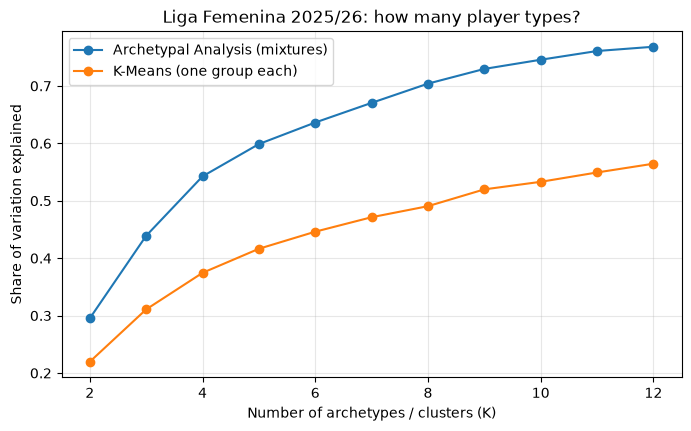

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(elbow["k"], elbow["aa_explained"], marker="o", label="Archetypal Analysis (mixtures)")
ax.plot(elbow["k"], elbow["kmeans_explained"], marker="o", label="K-Means (one group each)")
ax.set_xlabel("Number of archetypes / clusters (K)")
ax.set_ylabel("Share of variation explained")
ax.set_title("Liga Femenina 2025/26: how many player types?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Choosing K.** There is no single sharp elbow: gains are large up to K = 4 and fall below 3 points per extra
archetype after K = 8. We start with K = 8, as in the paper (which allows a direct comparison with its archetypes),
and confirm the choice by interpretability and stability.
At every K, mixtures (AA) explain far more than single groups (K-Means): 70% vs 49% at K = 8.

In [28]:
K = 8
aa = arch.AA(n_archetypes=K, random_state=42).fit(Z)

names = [f"A{i+1}" for i in range(K)]       # temporary names, until we understand them

# Each archetype back in real units (%, cm...), so we can read it
profiles = pd.DataFrame(scaler.inverse_transform(aa.archetypes_), columns=feature_cols, index=names)
profiles.round(1).T

,A1,A2,A3,A4,A5,A6,A7,A8
oreb_pct,15.2,2.9,11.1,4.5,7.9,1.9,4.5,1.5
dreb_pct,20.3,8.9,24.9,10.5,19.5,9.1,20.8,5.5
ast_pct,6.4,23.9,7.0,26.2,10.2,26.9,5.0,6.1
tov_pct,17.9,11.6,11.2,24.9,15.3,30.6,18.6,6.4
stl_pct,2.1,1.8,1.5,6.1,2.4,1.7,1.3,2.1
blk_pct,3.3,0.3,0.9,0.2,0.5,0.3,2.2,0.0
usg_pct,23.3,25.4,25.8,24.7,10.4,14.2,19.1,9.1
ft_rate,0.5,0.2,0.4,0.3,0.2,0.4,0.1,0.1
fg2_pct,0.5,0.4,0.7,0.5,0.7,0.3,0.4,0.3
fg3_pct,0.0,0.3,0.5,0.2,0.1,0.3,0.4,0.4


In [29]:
W = pd.DataFrame(aa.transform(Z), columns=names, index=sample_2025.index)   # each player's mix (rows sum to 1)

print("Weights sum to 1:", np.allclose(W.sum(axis=1), 1))

for a in names:
    top = W[a].nlargest(4)
    show = sample_2025.loc[top.index, ["player", "team", "position", "height"]].assign(weight=top.round(2))
    print(f"\n{a}")
    print(show.to_string(index=False))

Weights sum to 1: True

A1
                      player                    team position  height  weight
               FAYE, KHADIJA           IDK EUSKOTREN        C   193.0    1.00
          GIL COLLADO, LAURA    HOZONO GLOBAL JAIRIS        C   191.0    0.78
CAVE, KHADIJIAH DOCIA ANDREA     PERFUMERIAS AVENIDA        C   190.0    0.72
           GIOMI, LYDIA MORA DURÁN MAQUINARIA ENSINO        C   198.0    0.71

A2
                     player                              team position  height  weight
       BEN ABDELKADER, HIND                     VALENCIA B.C.       PG   172.0    0.86
           DUDASOVA, NIKOLA                INNOVA-TSN LEGANES       SG   178.0    0.83
  CONNER, MADISON ELIZABETH INGENIERÍA AMBIENTAL CAB ESTEPONA       SG   180.0    0.76
TOUSSAINT, DOMINIQUE NICOLE                  KUTXABANK ARASKI       SF   175.0    0.69

A3
                 player                              team position  height  weight
 COULIBALY, MARIAM ALOU                       SPAR GIRONA

## 5. Second run: fixing small samples
**What the first run showed:** some archetypes had extreme shooting values (100% free throws in A7, 0% threes in A1).
These come from players with very few attempts: a player who made 3 of 5 threes shows 60%, more than the best shooter
in the league. That is luck, not skill, and Archetypal Analysis is drawn to extremes.

**Fix:** every player starts with a few imaginary attempts at the league average (50 twos, 50 threes, 30 free throws).
Players with few attempts move towards the average; players with many barely change.
Example: 3/5 threes becomes (3 + 50 × 0.30) / (5 + 50) = 32.7%; 150/400 becomes 36.7% instead of 37.5%.

In [31]:
PRIOR = {"fg2": 50, "fg3": 50, "ft": 30}      # imaginary attempts at the league average

# League average from the 2025/26 sample (the same reference for both seasons, like the scaler)
league = players[2025][players[2025]["in_sample"]]
league_pct = {k: league[f"{k}_made"].sum() / league[f"{k}_att"].sum() for k in PRIOR}
print("League averages:", {k: round(v, 3) for k, v in league_pct.items()})

for s in [2025, 2026]:
    p, f = players[s], features[s]
    for k, n in PRIOR.items():
        f[f"{k}_pct"] = (p[f"{k}_made"] + n * league_pct[k]) / (p[f"{k}_att"] + n)
    f.to_csv(f"data/features_{s}.csv", index=False)       # the saved features are the corrected ones

sample_2025 = features[2025][features[2025]["in_sample"]]
sample_2025[["fg2_pct", "fg3_pct", "ft_pct"]].describe().T[["mean", "min", "max"]].round(3)

League averages: {'fg2': np.float64(0.473), 'fg3': np.float64(0.321), 'ft': np.float64(0.744)}


,mean,min,max
fg2_pct,0.467,0.362,0.645
fg3_pct,0.318,0.231,0.406
ft_pct,0.744,0.495,0.848


In [32]:
X_train = sample_2025[feature_cols].to_numpy()
scaler = StandardScaler().fit(X_train)
Z = scaler.transform(X_train)
total_ss = (Z ** 2).sum()

rows = []
for k in range(2, 13):
    aa_k = arch.AA(n_archetypes=k, random_state=42).fit(Z)
    aa_explained = 1 - ((Z - aa_k.transform(Z) @ aa_k.archetypes_) ** 2).sum() / total_ss
    km_explained = 1 - KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z).inertia_ / total_ss
    rows.append((k, aa_explained, km_explained))

elbow2 = pd.DataFrame(rows, columns=["k", "aa_explained", "kmeans_explained"])
elbow2["aa_gain"] = elbow2["aa_explained"].diff()            # how much each extra archetype adds
elbow2.round(3)

,k,aa_explained,kmeans_explained,aa_gain
0,2,0.295,0.219,NaN
1,3,0.438,0.313,0.143
2,4,0.544,0.380,0.106
3,5,0.598,0.422,0.054
4,6,0.630,0.444,0.032
5,7,0.652,0.469,0.022
6,8,0.689,0.496,0.038
7,9,0.693,0.509,0.004
8,10,0.719,0.525,0.026
9,11,0.754,0.544,0.035


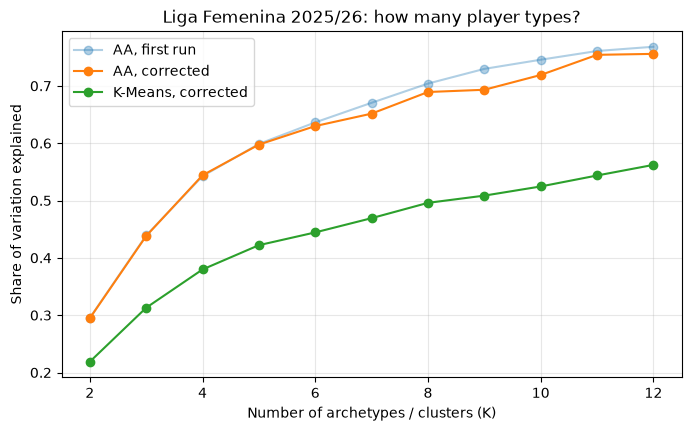

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(elbow["k"], elbow["aa_explained"], marker="o", alpha=0.35, label="AA, first run")
ax.plot(elbow2["k"], elbow2["aa_explained"], marker="o", label="AA, corrected")
ax.plot(elbow2["k"], elbow2["kmeans_explained"], marker="o", label="K-Means, corrected")
ax.set_xlabel("Number of archetypes / clusters (K)")
ax.set_ylabel("Share of variation explained")
ax.set_title("Liga Femenina 2025/26: how many player types?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [34]:
aa = arch.AA(n_archetypes=8, random_state=42).fit(Z)
aa9 = arch.AA(n_archetypes=9, random_state=42).fit(Z)
names = [f"A{i+1}" for i in range(8)]
names9 = [f"B{i+1}" for i in range(9)]

profiles = pd.DataFrame(scaler.inverse_transform(aa.archetypes_), columns=feature_cols, index=names)
profiles9 = pd.DataFrame(scaler.inverse_transform(aa9.archetypes_), columns=feature_cols, index=names9)

match = pd.DataFrame(cdist(aa.archetypes_, aa9.archetypes_), index=names, columns=names9)
new_one = match.min().idxmax()            # the K=9 archetype with no close partner in K=8
print("New archetype in K=9:", new_one)
match.round(1)

New archetype in K=9: B5


,B1,B2,B3,B4,B5,B6,B7,B8,B9
A1,1.5,6.9,6.4,7.3,7.7,9.7,3.4,9.7,5.1
A2,7.1,0.2,7.2,4.9,4.4,6.9,4.7,6.8,6.9
A3,6.9,6.2,3.5,7.7,7.1,7.1,5.5,7.4,3.1
A4,9.3,6.6,8.5,3.3,6.6,5.0,7.0,8.6,8.3
A5,5.4,4.5,8.0,5.1,3.9,7.5,5.4,6.5,7.1
A6,9.8,6.9,7.9,6.2,4.9,1.2,7.9,6.1,7.7
A7,5.5,6.9,5.0,7.4,6.7,7.5,4.6,8.5,2.6
A8,9.8,7.0,8.8,8.8,5.3,6.3,8.8,0.5,9.0


In [35]:
print(profiles.round(1).T)

W = pd.DataFrame(aa.transform(Z), columns=names, index=sample_2025.index)
for a in names:
    top = W[a].nlargest(4)
    show = sample_2025.loc[top.index, ["player", "team", "position", "height"]].assign(weight=top.round(2))
    print(f"\n{a}")
    print(show.to_string(index=False))

              A1     A2     A3     A4     A5     A6     A7     A8
oreb_pct    11.3    3.8    9.6    4.5    1.4    2.6   14.7    2.1
dreb_pct    26.4   13.7   18.9   10.3   10.3   11.4   19.8    7.0
ast_pct      7.3   22.0    7.5   26.5   17.4   26.5    7.1    6.4
tov_pct     13.4    8.7   16.8   24.8   13.1   31.2   17.5    7.1
stl_pct      1.6    1.5    1.5    6.0    1.7    2.4    2.0    2.1
blk_pct      0.6    0.2    3.5    0.2    0.6    0.3    1.6    0.1
usg_pct     27.1   24.8   19.0   24.3   25.1   14.9   20.4    9.4
ft_rate      0.4    0.2    0.3    0.3    0.2    0.3    0.6    0.1
fg2_pct      0.6    0.4    0.5    0.5    0.5    0.4    0.5    0.4
fg3_pct      0.4    0.3    0.3    0.3    0.4    0.3    0.3    0.3
ft_pct       0.8    0.7    0.6    0.7    0.8    0.8    0.8    0.7
pts_100     34.7   20.8   17.8   19.0   28.0   10.4   23.4    9.9
fga_100     22.9   23.8   16.0   18.3   22.5   10.3   15.4    9.7
fg3_share    0.2    0.3    0.1    0.4    0.6    0.4    0.1    0.8
height    

**Second run, results.**
- The shrinkage removed the false extremes (3P% now 23–41% instead of 0–60%; FT% 50–85% instead of 42–100%) while leaving the averages almost unchanged.
- **K = 8 is confirmed by the data:** the 9th archetype adds only 0.4 points of explained variation (the 8th adds 3.8), and K = 9 only reshuffles four existing archetypes instead of adding a new style.
- Mixtures still beat single groups: 68.9% (AA) vs 49.6% (K-Means) at K = 8.
- Two archetypes of the first run (a "stretch big" and a "low-usage finisher") disappeared: they were held up by shooting percentages on very few attempts.

## 6. Naming and stability
The eight archetypes get basketball names from their profiles and their purest players.
Then we test whether they are stable: Archetypal Analysis starts from a random point, so a good result
must come back when the starting point changes.

In [36]:
archetype_names = {
    "A1": "Interior Star",
    "A2": "Combo Creator",
    "A3": "Rim Protector",
    "A4": "Ball-Hawk Guard",
    "A5": "Scoring Wing",
    "A6": "Floor General",
    "A7": "Glass Cleaner",
    "A8": "Spot-Up Shooter",
}
labels = list(archetype_names.values())

profiles = profiles.rename(index=archetype_names)
W = W.rename(columns=archetype_names)
profiles.round(1).T

,Interior Star,Combo Creator,Rim Protector,Ball-Hawk Guard,Scoring Wing,Floor General,Glass Cleaner,Spot-Up Shooter
oreb_pct,11.3,3.8,9.6,4.5,1.4,2.6,14.7,2.1
dreb_pct,26.4,13.7,18.9,10.3,10.3,11.4,19.8,7.0
ast_pct,7.3,22.0,7.5,26.5,17.4,26.5,7.1,6.4
tov_pct,13.4,8.7,16.8,24.8,13.1,31.2,17.5,7.1
stl_pct,1.6,1.5,1.5,6.0,1.7,2.4,2.0,2.1
blk_pct,0.6,0.2,3.5,0.2,0.6,0.3,1.6,0.1
usg_pct,27.1,24.8,19.0,24.3,25.1,14.9,20.4,9.4
ft_rate,0.4,0.2,0.3,0.3,0.2,0.3,0.6,0.1
fg2_pct,0.6,0.4,0.5,0.5,0.5,0.4,0.5,0.4
fg3_pct,0.4,0.3,0.3,0.3,0.4,0.3,0.3,0.3


### Stability across starting points
We fit the same model (K = 8) with 10 different random starts. Each new set of archetypes is matched to our reference
one by one (the Hungarian algorithm finds the pairing with the smallest total distance). If an archetype is real,
it should come back close to the reference every time.
Threshold: a distance below 1.5 in z-score units (about 0.4 standard deviations per feature) counts as "found again".

In [37]:
from scipy.optimize import linear_sum_assignment

rows = []
for seed in range(10):
    aa_s = arch.AA(n_archetypes=8, random_state=seed).fit(Z)
    explained = 1 - ((Z - aa_s.transform(Z) @ aa_s.archetypes_) ** 2).sum() / total_ss

    D = cdist(aa.archetypes_, aa_s.archetypes_)          # reference (rows) vs this run (columns)
    ref_idx, new_idx = linear_sum_assignment(D)          # best one-to-one pairing
    for r, n in zip(ref_idx, new_idx):
        rows.append((seed, labels[r], D[r, n], explained))

stab = pd.DataFrame(rows, columns=["seed", "archetype", "distance", "explained"])

summary = stab.groupby("archetype")["distance"].agg(["median", "max"])
summary["found_pct"] = (stab["distance"] < 1.5).groupby(stab["archetype"]).mean() * 100
print(summary.round(2).sort_values("found_pct", ascending=False))

print("\nExplained variation per start:")
print(stab.groupby("seed")["explained"].first().round(3).to_dict())

                 median   max  found_pct
archetype                               
Spot-Up Shooter    0.35  1.64       80.0
Floor General      0.46  4.92       70.0
Ball-Hawk Guard    0.47  4.26       60.0
Combo Creator      1.17  5.54       50.0
Interior Star      1.51  2.44       50.0
Glass Cleaner      3.71  5.23       40.0
Scoring Wing       3.03  6.43       30.0
Rim Protector      3.34  3.87       10.0

Explained variation per start:
{0: 0.695, 1: 0.687, 2: 0.69, 3: 0.687, 4: 0.695, 5: 0.677, 6: 0.695, 7: 0.687, 8: 0.683, 9: 0.69}


**Stability result (K = 8, 10 random starts).** Guard and shooter archetypes are stable (Spot-Up Shooter, Floor General,
Ball-Hawk Guard: found again in 60–80% of runs). The big-player archetypes are not (Rim Protector 10%, Glass Cleaner 40%),
nor is the Scoring Wing (30%). Every run explains almost the same share of variation (67.7–69.5%): several different
solutions fit the data equally well, especially in how they split the space of interior players.
With 142 players for 8 archetypes (about 18 each), the borders between similar styles are weakly defined.
Also, our reference (seed 42) was not the best solution: seeds 0, 4 and 6 reach 69.5%.

**Next:** for K = 6, 7 and 8, keep the best of 20 starts as the reference (like `n_init` in K-Means) and measure how many
archetypes are stable. We choose the K whose archetypes are both interpretable and stable.

In [38]:
def fit_best(K, n_starts=20):
    """Fit AA with n_starts random starts. Returns all fits, best (highest explained variation) first."""
    fits = []
    for seed in range(n_starts):
        m = arch.AA(n_archetypes=K, random_state=seed).fit(Z)
        explained = 1 - ((Z - m.transform(Z) @ m.archetypes_) ** 2).sum() / total_ss
        fits.append((explained, seed, m))
    fits.sort(key=lambda t: t[0], reverse=True)
    return fits


def stability(fits, threshold=1.5):
    """For each archetype of the best fit: % of the other runs where it comes back (distance < threshold)."""
    best = fits[0][2]
    found = np.zeros(best.archetypes_.shape[0])
    for _, _, m in fits[1:]:
        D = cdist(best.archetypes_, m.archetypes_)
        r, n = linear_sum_assignment(D)
        found[r] += D[r, n] < threshold
    return found / (len(fits) - 1) * 100


results = {}
for K in [6, 7, 8]:
    results[K] = fit_best(K)
    pct = np.sort(stability(results[K]))[::-1]
    print(f"K={K} | best explained {results[K][0][0]:.3f} (seed {results[K][0][1]}) "
          f"| % found again, per archetype: {pct.round().astype(int).tolist()}")

K=6 | best explained 0.631 (seed 19) | % found again, per archetype: [100, 100, 58, 58, 37, 37]
K=7 | best explained 0.664 (seed 14) | % found again, per archetype: [89, 68, 58, 47, 47, 32, 21]
K=8 | best explained 0.695 (seed 0) | % found again, per archetype: [89, 74, 74, 58, 53, 42, 42, 26]


**Choosing K with stability.** For K = 6, 7 and 8, the best of 20 starts is the reference, and each archetype is tested
against the other 19 runs.

| K | Explained | Archetypes found again ≥ 70% | ≥ 50% |
|---|---|---|---|
| 6 | 63.1% | 2 of 6 | 4 of 6 |
| 7 | 66.4% | 1 of 7 | 3 of 7 |
| 8 | 69.5% | 3 of 8 | 5 of 8 |

Fewer archetypes do **not** make them stable: the instability belongs to the data, not to K. Some regions of the league
(guards, shooters) have well-defined styles; others (interior players, scoring wings) form a continuum that each run
cuts differently. We keep **K = 8** (most variation explained, most stable archetypes, comparable with the paper),
use the best of 20 starts as the final model, and report each archetype's stability next to its name.

In [39]:
aa_final = results[8][0][2]                         # best of 20 starts (seed 0)
stab_final = stability(results[8])                  # % found again, per archetype of aa_final

# Match the final archetypes to the named ones from the seed-42 model
D = cdist(aa.archetypes_, aa_final.archetypes_)
r, n = linear_sum_assignment(D)
mapping = pd.DataFrame({
    "name": [labels[i] for i in r],
    "final_index": n,
    "distance_to_old": D[r, n].round(2),
    "found_again_pct": stab_final[n].round(),
}).sort_values("final_index")
print(mapping.to_string(index=False))

# Profiles and purest players of the final model, with the matched names
final_names = mapping.sort_values("final_index")["name"].tolist()
profiles_final = pd.DataFrame(scaler.inverse_transform(aa_final.archetypes_), columns=feature_cols, index=final_names)
W_final = pd.DataFrame(aa_final.transform(Z), columns=final_names, index=sample_2025.index)

print()
print(profiles_final.round(1).T)
for a in final_names:
    top = W_final[a].nlargest(4)
    show = sample_2025.loc[top.index, ["player", "team", "position", "height"]].assign(weight=top.round(2))
    print(f"\n{a}")
    print(show.to_string(index=False))

           name  final_index  distance_to_old  found_again_pct
  Combo Creator            0             0.05             42.0
  Interior Star            1             2.44             42.0
  Glass Cleaner            2             5.21             74.0
   Scoring Wing            3             0.00             26.0
  Rim Protector            4             2.60             53.0
  Floor General            5             0.43             74.0
Spot-Up Shooter            6             0.12             89.0
Ball-Hawk Guard            7             0.23             58.0

           Combo Creator  Interior Star  Glass Cleaner  Scoring Wing  \
oreb_pct             3.8           13.8           10.9           1.4   
dreb_pct            13.8           22.3           18.9          10.3   
ast_pct             22.3            6.1            7.8          17.4   
tov_pct              8.8           15.5           18.1          13.1   
stl_pct              1.5            1.7            1.5           1.7   


**Final model (K = 8, best of 20 starts).** Five archetypes are almost identical to the seed-42 model and keep their names.
Three moved (Interior Star, Rim Protector, Glass Cleaner) but their profiles and purest players still match the names.
The Rim Protector now also takes some threes; its purest player is Nia Coffey, officially a small forward.

**Stability.** Solid (found again ≥ 70%): Spot-Up Shooter, Floor General, Glass Cleaner. Moderate (50–69%): Ball-Hawk Guard,
Rim Protector. Tentative (< 50%): Combo Creator, Interior Star, Scoring Wing.
The pattern follows usage: the stable archetypes are role players (usage 9–22%), the tentative ones are all
high-usage scorers (24–25%). Role players have a defined job and look alike; scorers each score in their own way,
so there is no clear "corner" for them. **Role players come in types; stars do not.**

In [40]:
final = mapping.sort_values("final_index").set_index("name")
final["usage"] = profiles_final["usg_pct"].round(1)
final["stability"] = pd.cut(final["found_again_pct"], bins=[0, 50, 70, 100],
                            labels=["tentative", "moderate", "solid"], right=False)
print(final[["found_again_pct", "stability", "usage"]].sort_values("found_again_pct", ascending=False))

profiles_final.to_csv("data/archetype_profiles.csv")
final.to_csv("data/archetype_stability.csv")

                 found_again_pct  stability  usage
name                                              
Spot-Up Shooter             89.0      solid    9.5
Glass Cleaner               74.0      solid   22.0
Floor General               74.0      solid   14.5
Ball-Hawk Guard             58.0   moderate   24.6
Rim Protector               53.0   moderate   18.5
Combo Creator               42.0  tentative   24.8
Interior Star               42.0  tentative   23.8
Scoring Wing                26.0  tentative   25.1


## 7. Archetypes vs official positions
Position was never used by the model. Now we compare: do the FEB's five positions describe how players actually play?

In [41]:
order = ["Floor General", "Ball-Hawk Guard", "Combo Creator", "Scoring Wing",
         "Spot-Up Shooter", "Rim Protector", "Interior Star", "Glass Cleaner"]   # from guards to bigs
pos_order = ["PG", "SG", "SF", "PF", "C", "none"]

res = sample_2025[["player", "team", "position", "height"]].join(W_final[order])
res["position"] = res["position"].fillna("none")
res["main_archetype"] = W_final[order].idxmax(axis=1)        # the archetype with the biggest weight
res["main_weight"] = W_final[order].max(axis=1)              # how big that weight is

print(f"Players whose main archetype is less than 50% of their mix: "
      f"{(res['main_weight'] < 0.5).mean() * 100:.0f}%")

pd.crosstab(res["position"], res["main_archetype"]).reindex(index=pos_order, columns=order, fill_value=0)

Players whose main archetype is less than 50% of their mix: 59%


main_archetype,Floor General,Ball-Hawk Guard,Combo Creator,Scoring Wing,Spot-Up Shooter,Rim Protector,Interior Star,Glass Cleaner
position,,,,,,,,
PG,13,6,3,8,4,0,2,0
SG,5,6,7,8,1,0,0,0
SF,2,0,2,6,8,3,3,1
PF,1,0,2,3,6,6,6,2
C,0,0,0,0,2,5,12,5
none,0,0,1,1,0,0,2,0


In [42]:
mix_by_pos = res.groupby("position")[order].mean().reindex(pos_order) * 100
mix_by_pos.round(0)

,Floor General,Ball-Hawk Guard,Combo Creator,Scoring Wing,Spot-Up Shooter,Rim Protector,Interior Star,Glass Cleaner
position,,,,,,,,
PG,32.0,20.0,14.0,15.0,12.0,1.0,2.0,3.0
SG,16.0,16.0,21.0,21.0,12.0,2.0,6.0,6.0
SF,10.0,4.0,7.0,20.0,29.0,13.0,14.0,4.0
PF,5.0,4.0,12.0,12.0,15.0,16.0,25.0,11.0
C,8.0,2.0,2.0,4.0,5.0,19.0,42.0,20.0
none,4.0,13.0,22.0,10.0,10.0,4.0,27.0,10.0


In [43]:
pos_group = {"PG": "guard", "SG": "guard", "SF": "wing", "PF": "big", "C": "big"}
arch_group = {"Floor General": "guard", "Ball-Hawk Guard": "guard", "Combo Creator": "guard",
              "Scoring Wing": "wing", "Spot-Up Shooter": "wing",
              "Rim Protector": "big", "Interior Star": "big", "Glass Cleaner": "big"}

res["pos_group"] = res["position"].map(pos_group)
res["arch_group"] = res["main_archetype"].map(arch_group)

surprises = res[(res["pos_group"] != res["arch_group"]) & res["pos_group"].notna() & (res["main_weight"] >= 0.5)]
surprises[["player", "team", "position", "height", "main_archetype", "main_weight"]] \
    .sort_values("main_weight", ascending=False).round(2)

,player,team,position,height,main_archetype,main_weight
201,"CONNER, MADISON ELIZABETH",INGENIERÍA AMBIENTAL CAB ESTEPONA,SG,180.0,Scoring Wing,1.00
149,"COFFEY, NIA",VALENCIA B.C.,SF,185.0,Rim Protector,0.97
225,"BIBBY, CHLOE LOUISE",SPAR GIRONA,PF,185.0,Scoring Wing,0.80
184,"JOINER, MOIRA MACY",BAXI FERROL,SG,177.0,Scoring Wing,0.68
148,"BEN ABDELKADER, HIND",VALENCIA B.C.,PG,172.0,Scoring Wing,0.62
41,"ROBINSON, PAIGE",IDK EUSKOTREN,SG,180.0,Scoring Wing,0.54
210,"HERLIHY, BRIANNA CAROLINA",INNOVA-TSN LEGANES,PF,187.0,Combo Creator,0.54
191,"RODRIGUEZ ARRIBAS, LUCIA",INGENIERÍA AMBIENTAL CAB ESTEPONA,PF,188.0,Spot-Up Shooter,0.53
79,"N'DIAYE, DJENEBA",SPAR GRAN CANARIA,PG,175.0,Scoring Wing,0.51


**Results.**
- **59% of players have no archetype above 50% of their mix**: for most players, no single label covers even half of what they do.
- **Positions work at the edges and blur in the middle.** Share of each position's average mix that falls in its own family
  of archetypes: C 81%, PG 66%, SG 53%, PF 52%, SF 49%. A typical SF is half wing and almost a third interior player;
  a typical PF is half interior and half perimeter.
- **Surprises** (main archetype in a different family than the official position, weight ≥ 50%): the clearest are
  Nia Coffey (SF, plays as a Rim Protector, 97%) and Chloe Bibby (PF, plays as a Scoring Wing, 80%), both 185 cm.
  SG players classed as Scoring Wings sit on a blurry border and are weaker surprises; the list depends on how
  positions and archetypes were grouped into families.

## 8. Player similarity (KNN)
"Who plays like X?" We look for the nearest players with cosine similarity, as in Class 10, in two spaces:
the 15 z-scored features (similar numbers) and the 8 archetype weights (similar role). Comparing both
shows whether the archetypes keep what makes a player distinctive.

In [44]:
iyana = res[res["player"].str.contains("MARTIN CARRION")]
print(iyana[["player", "team", "position", "height", "main_archetype"]].to_string(index=False))
(iyana[order] * 100).round(0)

               player                team position  height main_archetype
MARTIN CARRION, IYANA PERFUMERIAS AVENIDA       PG   176.0   Scoring Wing


,Floor General,Ball-Hawk Guard,Combo Creator,Scoring Wing,Spot-Up Shooter,Rim Protector,Interior Star,Glass Cleaner
49,0.0,38.0,13.0,50.0,0.0,0.0,0.0,0.0


In [45]:
from sklearn.neighbors import NearestNeighbors

spaces = {
    "features": Z,                                  # 15 z-scored features, same row order as sample_2025
    "archetypes": W_final[order].to_numpy(),        # 8 archetype weights, same row order
}

def similar_players(name_part, space, k=5):
    """The k players most similar to the first player whose name contains name_part, in one space."""
    X = spaces[space]
    i = np.where(sample_2025["player"].str.contains(name_part).to_numpy())[0][0]   # her row number
    knn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
    dist, idx = knn.kneighbors(X[i:i + 1])
    neighbours = idx[0][1:]                                                          # skip herself
    out = res.iloc[neighbours][["player", "team", "position", "height", "main_archetype"]].copy()
    out["similarity"] = (1 - dist[0][1:]).round(3)
    return out

for space in ["features", "archetypes"]:
    print(f"\nMost similar to Iyana Martín, in {space}:")
    print(similar_players("MARTIN CARRION", space).to_string(index=False))


Most similar to Iyana Martín, in features:
                  player                    team position  height main_archetype  similarity
     TATE, IMANI TY LEAH DURÁN MAQUINARIA ENSINO       SG   176.0   Scoring Wing       0.891
       GONZALES, SHAYLEE             CADI LA SEU       SG   180.0   Scoring Wing       0.802
CONTELL SANCHIS, CLAUDIA       SPAR GRAN CANARIA     none   177.0   Scoring Wing       0.768
ROMERO GONZALEZ, LETICIA           VALENCIA B.C.       PG   174.0   Scoring Wing       0.737
     ANDERSON, IVON MARC           VALENCIA B.C.       PG   175.0   Scoring Wing       0.678

Most similar to Iyana Martín, in archetypes:
                  player                    team position  height  main_archetype  similarity
     TATE, IMANI TY LEAH DURÁN MAQUINARIA ENSINO       SG   176.0    Scoring Wing       0.979
     RAVENTOS ROIG, LAIA             CADI LA SEU       SG   165.0 Ball-Hawk Guard       0.933
CONTELL SANCHIS, CLAUDIA       SPAR GRAN CANARIA     none   177.0    S

**Iyana Martín** is 50% Scoring Wing, 38% Ball-Hawk Guard, 13% Combo Creator and 0% Floor General: despite leading
the league in assists, she is a volume scorer who also pressures the ball, not a pass-first organiser.
**Features vs archetypes:** 4 of her 5 nearest players are the same in both spaces, with Imani Tate first in both.
Reducing 15 features to 8 archetype weights keeps what makes her style distinctive.

**Issue found:** Claudia Contell appears twice (Spar Gran Canaria and CAB Estepona). Season totals were grouped by
player URL, which contains the team id, so a player who changed clubs mid-season has one row per club.

In [46]:
for s in [2025, 2026]:
    f = features[s]
    dup_all = f[f["player_id"].duplicated(keep=False)]
    dup_sample = f[f["in_sample"] & f["player_id"].duplicated(keep=False)]
    print(f"{s}: {dup_all['player_id'].nunique()} players appear with two teams "
          f"({len(dup_sample)} of their rows are in the sample)")

dup = features[2025][features[2025]["player_id"].duplicated(keep=False)]
dup[["player", "team", "min", "in_sample", "height", "position"]].sort_values("player")

2025: 11 players appear with two teams (6 of their rows are in the sample)
2026: 0 players appear with two teams (0 of their rows are in the sample)


,player,team,min,in_sample,height,position
197,"ATKINSON, TANAYA MECHELLE",INGENIERÍA AMBIENTAL CAB ESTEPONA,213.433333,False,184.0,SF
142,"ATKINSON, TANAYA MECHELLE",VALENCIA B.C.,74.333333,False,NaN,NaN
145,"CHERY, KENDRA MARIE-CHRISTIANE",VALENCIA B.C.,72.016667,False,188.0,SF
127,"CHERY, KENDRA MARIE-CHRISTIANE",HOZONO GLOBAL JAIRIS,47.116667,False,188.0,SF
63,"CONTELL SANCHIS, CLAUDIA",SPAR GRAN CANARIA,330.966667,True,177.0,NaN
194,"CONTELL SANCHIS, CLAUDIA",INGENIERÍA AMBIENTAL CAB ESTEPONA,528.466667,True,178.0,PG
56,"ERIKSTRUP, LAURA ELAINE",PERFUMERIAS AVENIDA,65.650000,False,NaN,NaN
242,"ERIKSTRUP, LAURA ELAINE",MOVISTAR ESTUDIANTES,78.866667,False,188.0,PF
203,"GARRICK, MADELEINE CLAIRE",INGENIERÍA AMBIENTAL CAB ESTEPONA,403.000000,True,178.0,NaN
244,"GARRICK, MADELEINE CLAIRE",MOVISTAR ESTUDIANTES,216.283333,False,181.0,SF


**Player-team stints.** Season totals are per player **per team**: 11 players changed clubs in 2025/26 (none so far
in 2026/27). In the model sample this means one player appears twice (Claudia Contell, two stints above 300 minutes)
and two players are missing (Marie Mane and Aaronette Vonleh: each stint is below 300 minutes, but together they pass).
We keep stints separate: each row uses the context of the team the player was in, which is a common choice in
basketball analytics, and the effect is small (1 duplicate and 2 missing out of 142). Merging stints is left as a next step.
**Heights:** the FEB had heights for some of the hand-filled players in their *other* stint of the same season
(e.g. Garrick 181 cm at Estudiantes, FIBA says 178). Official sources disagree by 1–3 cm; the difference does not affect the model.

In [48]:
def similar_players(name_part, space, k=5):
    """The k players most similar to the first player whose name contains name_part.
    Excludes the player herself and her other stints (same player_id)."""
    X = spaces[space]
    i = np.where(sample_2025["player"].str.contains(name_part).to_numpy())[0][0]
    me = sample_2025["player_id"].iloc[i]

    knn = NearestNeighbors(n_neighbors=k + 3, metric="cosine").fit(X)    # a few extra, some will be dropped
    dist, idx = knn.kneighbors(X[i:i + 1])

    keep = [(j, d) for j, d in zip(idx[0], dist[0]) if sample_2025["player_id"].iloc[j] != me][:k]
    out = res.iloc[[j for j, _ in keep]][["player", "team", "position", "height", "main_archetype"]].copy()
    out["similarity"] = [round(1 - d, 3) for _, d in keep]
    return out

print(similar_players("CONTELL", "archetypes").to_string(index=False))

               player                    team position  height  main_archetype  similarity
  RAVENTOS ROIG, LAIA             CADI LA SEU       SG   165.0 Ball-Hawk Guard       0.938
MARTIN CARRION, IYANA     PERFUMERIAS AVENIDA       PG   176.0    Scoring Wing       0.932
  TATE, IMANI TY LEAH DURÁN MAQUINARIA ENSINO       SG   176.0    Scoring Wing       0.913
 LAMANA LLOBERA, LAIA  CLUB JOVENTUT BADALONA       PG   170.0 Ball-Hawk Guard       0.867
    GONZALES, SHAYLEE             CADI LA SEU       SG   180.0    Scoring Wing       0.821


**Similarity results.** Claudia Contell's nearest players (Raventós, Iyana Martín, Tate, Lamana, Gonzales) almost
coincide with Iyana Martín's: there is a tight family of 6–7 guards (PG and SG, 165–180 cm) who score a lot and
pressure the ball, a mix of Scoring Wing and Ball-Hawk Guard that no official position describes.
Contell's two 2025/26 stints have different main archetypes (Scoring Wing at Gran Canaria, Ball-Hawk Guard at Estepona):
the same player changed role when she changed club, which supports keeping stints separate.

## 9. Projecting 2026/27
The 2026/27 players are placed on the 2025/26 model: same scaler, same archetypes, nothing is refitted.
For players in both samples, we compare their mixes to see who changed role.
Caution: 2026/27 has only 7 rounds, so its numbers are noisier than a full season.

In [50]:
sample_2026 = features[2026][features[2026]["in_sample"]]
Z26 = scaler.transform(sample_2026[feature_cols].to_numpy())          # the 2025/26 ruler
W26 = pd.DataFrame(aa_final.transform(Z26), columns=final_names, index=sample_2026.index)[order]

res26 = sample_2026[["player_id", "player", "team", "position", "height", "min"]].join(W26)
res26["main_archetype"] = W26.idxmax(axis=1)

# 2025/26: one row per player, the stint with the most minutes
res25 = res.join(sample_2025[["player_id", "min"]])
res25_main = res25.sort_values("min", ascending=False).drop_duplicates("player_id")

both = res25_main.merge(res26, on="player_id", suffixes=("_25", "_26"))
w25 = both[[f"{a}_25" for a in order]].to_numpy()
w26 = both[[f"{a}_26" for a in order]].to_numpy()
both["role_change"] = 0.5 * np.abs(w25 - w26).sum(axis=1)             # 0 = same mix, 1 = completely different

kept = (both["main_archetype_25"] == both["main_archetype_26"]).mean() * 100
print(f"{len(both)} players in both samples; {kept:.0f}% kept their main archetype")

both.sort_values("role_change", ascending=False)[
    ["player_26", "team_25", "team_26", "main_archetype_25", "main_archetype_26", "role_change"]
].head(10).round(2)

77 players in both samples; 55% kept their main archetype


,player_26,team_25,team_26,main_archetype_25,main_archetype_26,role_change
10,"JOINER, MOIRA MACY",BAXI FERROL,INNOVA-TSN LEGANÉS,Scoring Wing,Combo Creator,0.97
53,"ORSILI, ALESSANDRA",DURÁN MAQUINARIA ENSINO,CADI LA SEU,Floor General,Ball-Hawk Guard,0.94
40,"VORACKOVA, VERONIKA",CASADEMONT ZARAGOZA,CASADEMONT ZARAGOZA,Floor General,Rim Protector,0.89
32,"ARIZTIMUÑO LOPEZ, ITZIAR",IDK EUSKOTREN,MIRAI EUSKOTREN,Floor General,Spot-Up Shooter,0.87
71,"OSMA CRUZ, CARLA",MOVISTAR ESTUDIANTES,MOVISTAR ESTUDIANTES,Spot-Up Shooter,Combo Creator,0.80
7,"CONNER, MADISON ELIZABETH",INGENIERÍA AMBIENTAL CAB ESTEPONA,SPAR GIRONA,Scoring Wing,Combo Creator,0.80
35,"EJIM, YVONNE UJU",IDK EUSKOTREN,AZULMARINO MALLORCA PALMA,Interior Star,Floor General,0.73
39,"PEREZ ARAUJO, MARIA",VALENCIA B.C.,VALENCIA B.C.,Rim Protector,Interior Star,0.66
1,"OLAETA LARRAURI, ANE",LOINTEK GERNIKA BIZKAIA,INVERSUS GERNIKA BIZKAIA,Scoring Wing,Floor General,0.64
3,"TATE, IMANI TY LEAH",DURÁN MAQUINARIA ENSINO,MIRAI EUSKOTREN,Scoring Wing,Combo Creator,0.62


**First look:** 77 players are in both samples and 55% keep their main archetype. Some changes are plausible
(Joiner and Conner, Scoring Wing → Combo Creator after changing clubs); others are not (Voráčková, same team,
Floor General → Rim Protector). With only 7 rounds, part of the change is sampling noise.

### Noise baseline
How much does a player's mix move by chance alone after 7 games? We take 2025/26 rounds 1–7 only and compare
with the full 2025/26 season: same player, same team, same season, so any difference is noise. Only 2026/27 changes
clearly above this baseline are treated as real role changes.

In [51]:
sum_cols = ["min", "pts", "oreb", "dreb", "ast", "stl", "tov", "blk",
            "fg2_made", "fg2_att", "fg3_made", "fg3_att", "fg_made", "fg_att", "ft_made", "ft_att"]

early = box[2025][box[2025]["round"] <= 7]                       # 2025/26, rounds 1-7 only

# Players: totals per player-team stint, plus height and position from the prepared table
p7 = early.groupby(["player_url", "team"])[sum_cols].sum().reset_index()
p7 = p7.merge(players[2025][["player_url", "player_id", "player", "position", "height"]], on="player_url")
p7["in_sample"] = p7["min"] >= 70                                # the same filter as 2026/27

# Team and opponent context for the same 7 rounds, from the box scores
t7 = early.groupby("team")[["min", "fg_made", "fg_att", "oreb", "dreb", "tov", "ft_att"]].sum()
t7["poss"] = t7["fg_att"] - t7["oreb"] + t7["tov"] + 0.44 * t7["ft_att"]
o7 = early.groupby("opponent")[opp_cols].sum().add_prefix("opp_")
o7["opp_poss"] = o7["opp_fg_att"] - o7["opp_oreb"] + o7["opp_tov"] + 0.44 * o7["opp_ft_att"]
ctx7 = t7.add_prefix("team_").join(o7)

# Same features, same shrinkage, same scaler, same model
f7 = build_features(p7, ctx7)
for k, n in PRIOR.items():
    f7[f"{k}_pct"] = (p7[f"{k}_made"] + n * league_pct[k]) / (p7[f"{k}_att"] + n)

s7 = f7[f7["in_sample"]]
W7 = pd.DataFrame(aa_final.transform(scaler.transform(s7[feature_cols].to_numpy())),
                  columns=final_names, index=s7.index)[order]
W7["player_url"] = p7.loc[s7.index, "player_url"].to_numpy()
print(len(W7), "player stints with 70+ minutes in rounds 1-7 of 2025/26")

ValueError: Input X contains NaN.
AA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

The cell above fails: some features contain missing values (NaN) for rounds 1–7. We check where they come from before fixing.

In [52]:
nan_cols = s7[feature_cols].isna().sum()
print("Features with NaN:")
print(nan_cols[nan_cols > 0])

print("\nPlayers affected:")
print(s7.loc[s7[feature_cols].isna().any(axis=1), ["player", "team"] + list(nan_cols[nan_cols > 0].index)])

print("\nNaN in the team context:", ctx7.isna().sum().sum())

Features with NaN:
height    11
dtype: int64

Players affected:
                                    player                  team  height
20           WERTH, FREJA FELICIA KRISTINA           CADI LA SEU     NaN
44                     STOUPALOVA, NATALIE   PERFUMERIAS AVENIDA     NaN
50                   SHERRILL, RUTH HELENA     SPAR GRAN CANARIA     NaN
52   HERIAUD, CAROLINE VERONIQUE DOMINIQUE     SPAR GRAN CANARIA     NaN
88                 WALKER, JASMINE JABRELL  HOZONO GLOBAL JAIRIS     NaN
90                    CVITKOVIC, ANDRIJANA  HOZONO GLOBAL JAIRIS     NaN
97               ATKINSON, TANAYA MECHELLE         VALENCIA B.C.     NaN
99                         IAGUPOVA, ALINA         VALENCIA B.C.     NaN
112               LAWRENCE, ALYSSA JULIANA      KUTXABANK ARASKI     NaN
170                AMIHERE, LAETICIA EJOBA           SPAR GIRONA     NaN
182                   ODOM, LEAONNA LANEAH  MOVISTAR ESTUDIANTES     NaN

NaN in the team context: 0


The NaN are 11 heights: players with 70+ minutes in rounds 1–7 who did not reach 300 minutes over the full season
(several left mid-season), so they are not in the 2025/26 sample and their heights were never completed.
They could not be compared with a full-season mix anyway, so we keep only the stints present in both versions.

In [53]:
full_urls = set(players[2025].loc[sample_2025.index, "player_url"])   # stints in the full-season sample

s7 = f7[f7["in_sample"] & p7["player_url"].isin(full_urls)]
print(len(s7), "stints in both versions | NaN left:", s7[feature_cols].isna().sum().sum())

W7 = pd.DataFrame(aa_final.transform(scaler.transform(s7[feature_cols].to_numpy())),
                  columns=final_names, index=s7.index)[order]
W7["player_url"] = p7.loc[s7.index, "player_url"].to_numpy()

118 stints in both versions | NaN left: 0


In [54]:
Wfull = W_final[order].copy()
Wfull["player_url"] = players[2025].loc[sample_2025.index, "player_url"].to_numpy()

pair = W7.merge(Wfull, on="player_url", suffixes=("_7", "_full"))
a = pair[[f"{x}_7" for x in order]].to_numpy()
b = pair[[f"{x}_full" for x in order]].to_numpy()
pair["noise_change"] = 0.5 * np.abs(a - b).sum(axis=1)

kept_noise = (a.argmax(axis=1) == b.argmax(axis=1)).mean() * 100

print(f"Noise baseline ({len(pair)} stints): median change {pair['noise_change'].median():.2f}, "
      f"90th percentile {pair['noise_change'].quantile(0.9):.2f}, kept main archetype {kept_noise:.0f}%")
print(f"2025/26 → 2026/27 ({len(both)} players): median change {both['role_change'].median():.2f}, "
      f"kept main archetype {kept:.0f}%")

Noise baseline (118 stints): median change 0.25, 90th percentile 0.50, kept main archetype 61%
2025/26 → 2026/27 (77 players): median change 0.42, kept main archetype 55%


**Result.** By chance alone, 7 rounds move a player's mix by a median of 0.25 and only 61% keep their full-season
main archetype. Between seasons the median change is 0.42 and 55% keep it. So:
- the **main archetype after 7 rounds is unreliable**: most 2026/27 "archetype switches" are within what noise alone produces;
- the **mix does move more than noise** (0.42 vs 0.25), so there is real season-to-season change;
- the 90th percentile of noise (0.50) is our threshold: changes above it are unlikely to be noise alone.

Because rounds 1–7 are part of the full season, this baseline slightly underestimates the noise, which makes the conclusion conservative.

In [55]:
noise_p90 = pair["noise_change"].quantile(0.9)

real = both[both["role_change"] > noise_p90].sort_values("role_change", ascending=False)
print(f"{len(real)} of {len(both)} players changed more than the noise 90th percentile ({noise_p90:.2f})")
print(f"By chance alone we would expect about {0.1 * len(both):.0f}")

real[["player_26", "team_25", "team_26", "main_archetype_25", "main_archetype_26", "role_change"]]

23 of 77 players changed more than the noise 90th percentile (0.50)
By chance alone we would expect about 8


,player_26,team_25,team_26,main_archetype_25,main_archetype_26,role_change
10,"JOINER, MOIRA MACY",BAXI FERROL,INNOVA-TSN LEGANÉS,Scoring Wing,Combo Creator,0.970719
53,"ORSILI, ALESSANDRA",DURÁN MAQUINARIA ENSINO,CADI LA SEU,Floor General,Ball-Hawk Guard,0.939987
40,"VORACKOVA, VERONIKA",CASADEMONT ZARAGOZA,CASADEMONT ZARAGOZA,Floor General,Rim Protector,0.889091
32,"ARIZTIMUÑO LOPEZ, ITZIAR",IDK EUSKOTREN,MIRAI EUSKOTREN,Floor General,Spot-Up Shooter,0.873532
71,"OSMA CRUZ, CARLA",MOVISTAR ESTUDIANTES,MOVISTAR ESTUDIANTES,Spot-Up Shooter,Combo Creator,0.804295
7,"CONNER, MADISON ELIZABETH",INGENIERÍA AMBIENTAL CAB ESTEPONA,SPAR GIRONA,Scoring Wing,Combo Creator,0.803153
35,"EJIM, YVONNE UJU",IDK EUSKOTREN,AZULMARINO MALLORCA PALMA,Interior Star,Floor General,0.726532
39,"PEREZ ARAUJO, MARIA",VALENCIA B.C.,VALENCIA B.C.,Rim Protector,Interior Star,0.662798
1,"OLAETA LARRAURI, ANE",LOINTEK GERNIKA BIZKAIA,INVERSUS GERNIKA BIZKAIA,Scoring Wing,Floor General,0.644070
3,"TATE, IMANI TY LEAH",DURÁN MAQUINARIA ENSINO,MIRAI EUSKOTREN,Scoring Wing,Combo Creator,0.623996


**Changes above noise.** 23 of 77 players change more than the noise 90th percentile, against about 8 expected by
chance: there is real role change between seasons, but roughly a third of this list is still noise, so we read it
as a group, not player by player. Two patterns stand out: about half of the list changed clubs, and 7 players move
towards Interior Star, several without changing clubs. We test both: are club changers over-represented, and has the
league's average mix shifted in early 2026/27?

In [57]:
# 1. Club changers (two sponsor renames are the same club)
renamed = {"IDK EUSKOTREN": "MIRAI EUSKOTREN", "LOINTEK GERNIKA BIZKAIA": "INVERSUS GERNIKA BIZKAIA"}
both["moved"] = both["team_25"].replace(renamed) != both["team_26"]
both["above_noise"] = both["role_change"] > noise_p90

print(both.groupby("moved").agg(players=("above_noise", "size"),
                                 share_above_noise=("above_noise", "mean"),
                                 median_change=("role_change", "median")).round(2))

# 2. League-level shift: average archetype weight in each season (same 77 players)
shift = pd.DataFrame({"2025/26": both[[f"{x}_25" for x in order]].mean().to_numpy(),
                      "2026/27": both[[f"{x}_26" for x in order]].mean().to_numpy()}, index=order)
shift["difference"] = shift["2026/27"] - shift["2025/26"]
shift.round(3)

       players  share_above_noise  median_change
moved                                           
False       35               0.31           0.39
True        42               0.29           0.42


,2025/26,2026/27,difference
Floor General,0.171,0.170,-0.001
Ball-Hawk Guard,0.113,0.145,0.032
Combo Creator,0.118,0.128,0.010
Scoring Wing,0.126,0.099,-0.028
Spot-Up Shooter,0.183,0.159,-0.024
Rim Protector,0.077,0.082,0.005
Interior Star,0.134,0.162,0.028
Glass Cleaner,0.076,0.055,-0.022


**League-level shift.** The average mix barely moves between seasons (all differences ≤ 0.03): Ball-Hawk Guard and
Interior Star rise slightly, Spot-Up Shooter, Scoring Wing and Glass Cleaner fall slightly. There is no strong
league-wide drift, so the changes above noise are spread across players rather than one global effect.

**Club changers (check).** The test above counts 42 of 77 players as club changers, which is too many: more teams
than the two we mapped only changed sponsor name. We list the team names of both seasons and complete the mapping.

In [58]:
t25 = set(teams[2025]["team"])
t26 = set(teams[2026]["team"])
print("Only in 2025/26:", sorted(t25 - t26))
print("Only in 2026/27:", sorted(t26 - t25))

Only in 2025/26: ['CLUB JOVENTUT BADALONA', 'IDK EUSKOTREN', 'INGENIERÍA AMBIENTAL CAB ESTEPONA', 'INNOVA-TSN LEGANES', 'LOINTEK GERNIKA BIZKAIA', 'PERFUMERIAS AVENIDA', 'SPAR GRAN CANARIA']
Only in 2026/27: ['AZULMARINO MALLORCA PALMA', 'CELTA FEMXA ZORKA', 'IMPULSO 360 ESTEPONA', 'INNOVA-TSN LEGANÉS', 'INVERSUS GERNIKA BIZKAIA', 'MEINS AVENIDA', 'MIRAI EUSKOTREN']


Five teams only changed name between seasons (four sponsor changes, plus "Leganes" → "Leganés", an accent only).
Joventut Badalona and Gran Canaria were relegated; Mallorca and Celta Zorka were promoted. We map the five renames
and repeat the club-changer test.

In [59]:
renamed = {"IDK EUSKOTREN": "MIRAI EUSKOTREN",
           "LOINTEK GERNIKA BIZKAIA": "INVERSUS GERNIKA BIZKAIA",
           "PERFUMERIAS AVENIDA": "MEINS AVENIDA",
           "INGENIERÍA AMBIENTAL CAB ESTEPONA": "IMPULSO 360 ESTEPONA",
           "INNOVA-TSN LEGANES": "INNOVA-TSN LEGANÉS"}

both["moved"] = both["team_25"].replace(renamed) != both["team_26"]
print(both["moved"].sum(), "of", len(both), "players changed clubs")

print(both.groupby("moved").agg(players=("above_noise", "size"),
                                 share_above_noise=("above_noise", "mean"),
                                 median_change=("role_change", "median")).round(2))

35 of 77 players changed clubs
       players  share_above_noise  median_change
moved                                           
False       42               0.26           0.38
True        35               0.34           0.46


**Club changers.** With the five renames mapped, 35 of 77 players changed clubs. They are more often above the noise
threshold (34% vs 26%) and change more (median 0.46 vs 0.38), consistent with a new team bringing a new role. The
groups are small (12 vs 11 players above noise), so this is suggestive, not conclusive. Players who stayed also change
above noise far more often than chance (26% vs 10%): roles move between seasons even without a transfer.

### Summary of the 2026/27 projection
- After 7 rounds, a player's **main archetype is unreliable**: noise alone changes it for 39% of players.
- The **mix moves more than noise** between seasons (median 0.42 vs 0.25): 23 of 77 players change above the noise
  90th percentile, against about 8 expected by chance.
- There is **no strong league-wide shift** (average weights move by at most 0.03).
- **Changing clubs adds a little**, but roles also change for players who stay.
- **Practical rule:** read early-season archetypes as a mix with uncertainty, not as a label; re-check after more rounds.

## 10. Saving the results
The model's outputs are saved so that `03_results.ipynb` can use them without refitting.

In [60]:
info = players[2025].loc[sample_2025.index, ["player_url"]].join(sample_2025[["player_id", "min"]])

mix25 = info.join(res.drop(columns=["player_id", "min"], errors="ignore"))
mix25.to_csv("data/archetype_mix_2025.csv", index=False)

res26.to_csv("data/archetype_mix_2026.csv", index=False)
both.to_csv("data/archetype_change.csv", index=False)

zs = pd.DataFrame(Z, columns=feature_cols, index=sample_2025.index).join(sample_2025[["player_id"]])
zs.to_csv("data/zscores_2025.csv", index=False)

print(mix25.shape, res26.shape, both.shape, zs.shape)

(142, 19) (142, 15) (77, 35) (142, 16)


## 11. Method figures
Figures for the methods and robustness sections: model choice (elbow), archetype stability across seeds, and
early-season noise versus real role change.

In [61]:
print(len(pair), round(noise_p90, 2), len(both))
print(elbow2.head(3))
print(final.head(3))

118 0.5 77
   k  aa_explained  kmeans_explained   aa_gain
0  2      0.294686          0.218781       NaN
1  3      0.438104          0.312940  0.143419
2  4      0.544012          0.379733  0.105908
               final_index  distance_to_old  found_again_pct  usage  stability
name                                                                          
Combo Creator            0             0.05             42.0   24.8  tentative
Interior Star            1             2.44             42.0   23.8  tentative
Glass Cleaner            2             5.21             74.0   22.0      solid


**Figure: model choice.** Share of variation explained by Archetypal Analysis and K-Means for K = 2 to 10. AA explains
more at every K, and the gain flattens after K = 8 (adding a ninth archetype adds only 0.004).

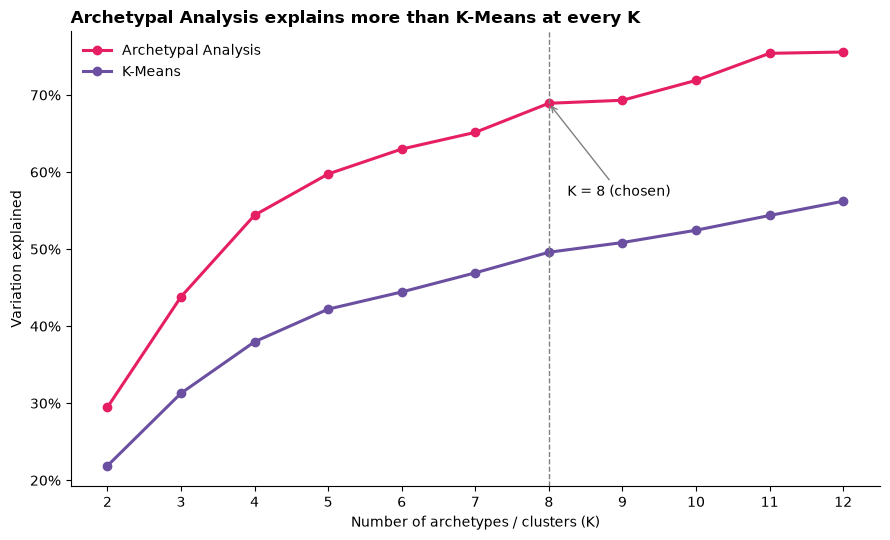

In [62]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(elbow2["k"], elbow2["aa_explained"], marker="o", lw=2.2, color="#e61e63", label="Archetypal Analysis")
ax.plot(elbow2["k"], elbow2["kmeans_explained"], marker="o", lw=2.2, color="#6b4fa0", label="K-Means")

ax.axvline(8, color="grey", ls="--", lw=1)
k8 = elbow2.loc[elbow2["k"] == 8].iloc[0]
ax.annotate("K = 8 (chosen)", xy=(8, k8["aa_explained"]), xytext=(8.25, k8["aa_explained"] - 0.12),
            fontsize=10, arrowprops=dict(arrowstyle="->", color="grey"))

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_xticks(elbow2["k"])
ax.set_xlabel("Number of archetypes / clusters (K)")
ax.set_ylabel("Variation explained")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title("Archetypal Analysis explains more than K-Means at every K", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/elbow_aa_vs_kmeans.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure: model choice.** Archetypal Analysis explains more variation than K-Means at every K (69% vs 50% at K = 8).
The curve has no single sharp elbow: the gain is almost flat from 8 to 9 (+0.4 points) but rises again at 10 and 11.
K = 8 is chosen on three grounds together: the 8 → 9 plateau, the basketball interpretability of the eight archetypes,
and stability (more archetypes split 142 players into smaller, less reproducible groups). The final model, fitted with
20 starts, explains 69.5%.

**Figure: stability follows usage.** Share of 20 refits (different seeds) in which each archetype is found again,
against its typical usage rate. Low-usage role archetypes are reproducible; high-usage creator and scorer archetypes are
not: role players come in types, stars do not.

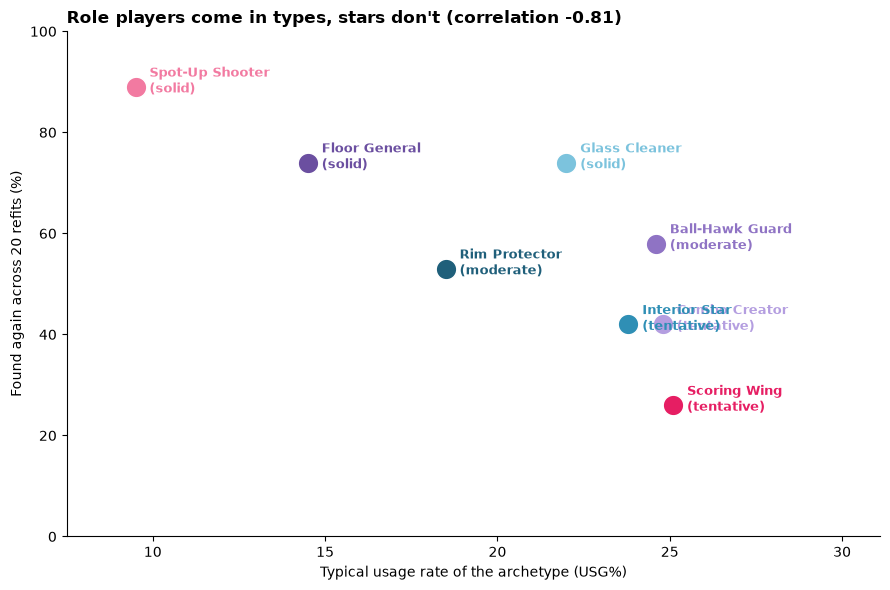

In [63]:
arch_colors = {"Floor General": "#6b4fa0", "Ball-Hawk Guard": "#8f73c4", "Combo Creator": "#b49ee0",
               "Scoring Wing": "#e61e63", "Spot-Up Shooter": "#f27aa1",
               "Rim Protector": "#1f5f7a", "Interior Star": "#2f8fb5", "Glass Cleaner": "#7cc3dd"}

st = final[["found_again_pct", "usage", "stability"]].copy()
r = st["usage"].corr(st["found_again_pct"])

fig, ax = plt.subplots(figsize=(9, 6))
for a, row in st.iterrows():
    ax.scatter(row["usage"], row["found_again_pct"], s=220, color=arch_colors[a], edgecolor="white", zorder=3)
    ax.annotate(f"{a}\n({row['stability']})", (row["usage"], row["found_again_pct"]),
                xytext=(10, -4), textcoords="offset points", fontsize=9.5, color=arch_colors[a], fontweight="bold")

ax.set_xlabel("Typical usage rate of the archetype (USG%)")
ax.set_ylabel("Found again across 20 refits (%)")
ax.set_ylim(0, 100)
ax.set_xlim(st["usage"].min() - 2, st["usage"].max() + 6)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Role players come in types, stars don't (correlation {r:.2f})", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/stability_vs_usage.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the figure.** The correlation between usage and stability is −0.81: low-usage role archetypes (Spot-Up
Shooter, Floor General) are reproducible, while high-usage scorers and creators (Scoring Wing, Combo Creator, Interior
Star) are not. Glass Cleaner is the exception (usage 22%, solid), probably because it is defined by physical traits
(height, offensive rebounding) rather than by what the player does with the ball. A fuller reading: roles defined by a
clear specialty are stable; roles defined by creating and scoring are not. With only eight points this illustrates the
pattern rather than testing it. The version below fixes two overlapping labels.

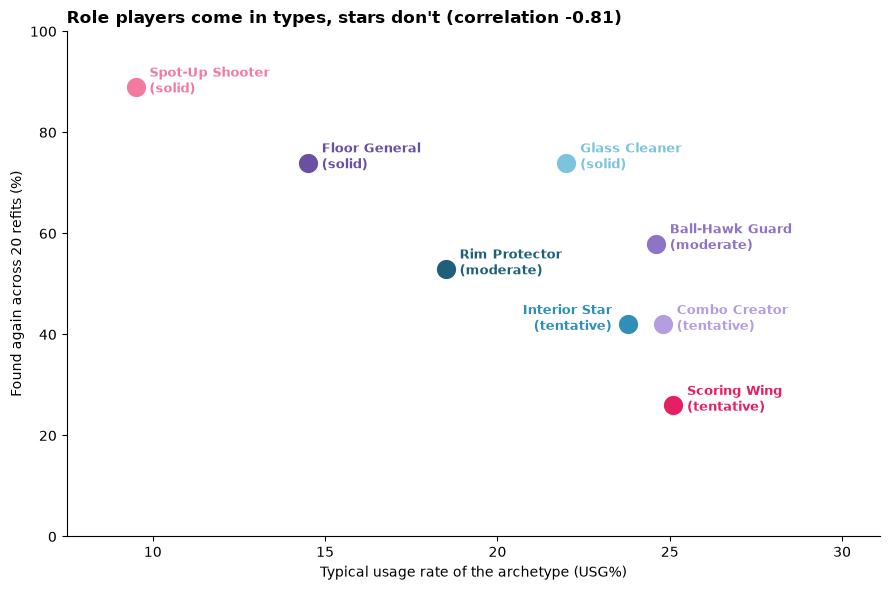

In [64]:
offsets = {a: (10, -4, "left") for a in st.index}
offsets["Interior Star"] = (-12, -4, "right")                  # label to the left of the point

fig, ax = plt.subplots(figsize=(9, 6))
for a, row in st.iterrows():
    dx, dy, ha = offsets[a]
    ax.scatter(row["usage"], row["found_again_pct"], s=220, color=arch_colors[a], edgecolor="white", zorder=3)
    ax.annotate(f"{a}\n({row['stability']})", (row["usage"], row["found_again_pct"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha,
                fontsize=9.5, color=arch_colors[a], fontweight="bold")

ax.set_xlabel("Typical usage rate of the archetype (USG%)")
ax.set_ylabel("Found again across 20 refits (%)")
ax.set_ylim(0, 100)
ax.set_xlim(st["usage"].min() - 2, st["usage"].max() + 6)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Role players come in types, stars don't (correlation {r:.2f})", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/stability_vs_usage.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure: noise versus real role change.** Distribution of the change in archetype mix (0 = identical, 1 = completely
different) for two comparisons: rounds 1–7 vs the full 2025/26 season for the same player (noise only), and 2025/26 vs
2026/27 (real change plus noise). The dashed line is the 90th percentile of noise (0.50). Between seasons, 30% of
players exceed it, three times the 10% expected by chance.

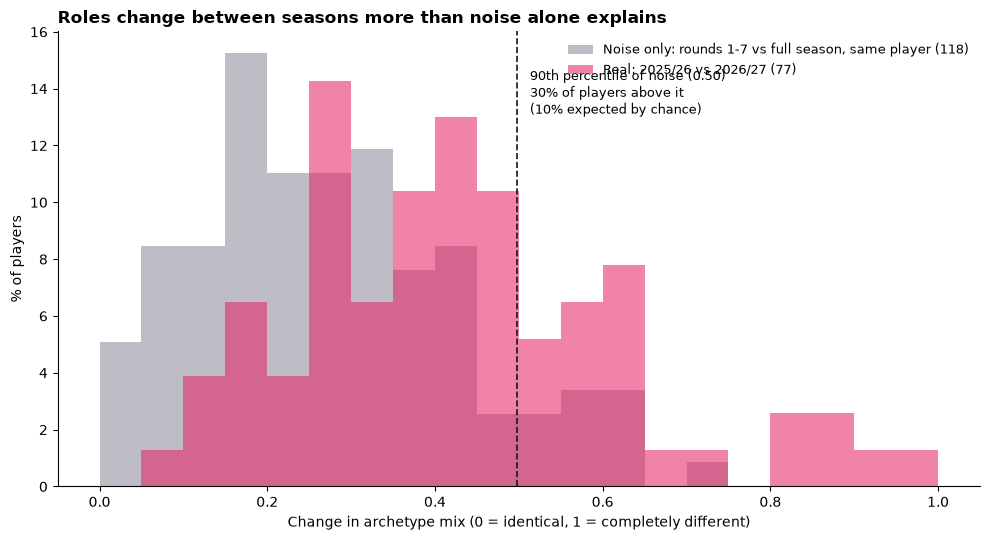

In [65]:
bins = np.linspace(0, 1, 21)                                           # 20 bins of width 0.05
w_noise = np.ones(len(pair)) / len(pair) * 100                          # each player counts as % of her group
w_real = np.ones(len(both)) / len(both) * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(pair["noise_change"], bins=bins, weights=w_noise, color="#a9a6b0", alpha=0.75,
        label=f"Noise only: rounds 1-7 vs full season, same player ({len(pair)})")
ax.hist(both["role_change"], bins=bins, weights=w_real, color="#e61e63", alpha=0.55,
        label=f"Real: 2025/26 vs 2026/27 ({len(both)})")

ax.axvline(noise_p90, color="#16161a", ls="--", lw=1.2)
share_above = (both["role_change"] > noise_p90).mean() * 100
ax.text(noise_p90 + 0.015, ax.get_ylim()[1] * 0.92,
        f"90th percentile of noise ({noise_p90:.2f})\n{share_above:.0f}% of players above it\n(10% expected by chance)",
        fontsize=9.5, va="top")

ax.set_xlabel("Change in archetype mix (0 = identical, 1 = completely different)")
ax.set_ylabel("% of players")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Roles change between seasons more than noise alone explains", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/noise_vs_change.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading the figure.** Noise alone (grey) peaks around 0.15–0.25 and rarely exceeds 0.6. Real change (pink) is
shifted right, peaking around 0.25–0.45, and only real change reaches the 0.75–1.0 tail (Joiner, Orsili, Voráčková,
Ariztimuño, Osma, Conner). Individual early-season labels are unreliable, but role change across the league exceeds
noise, and the most extreme changes cannot be explained by chance. The version below moves the annotation away from the legend.

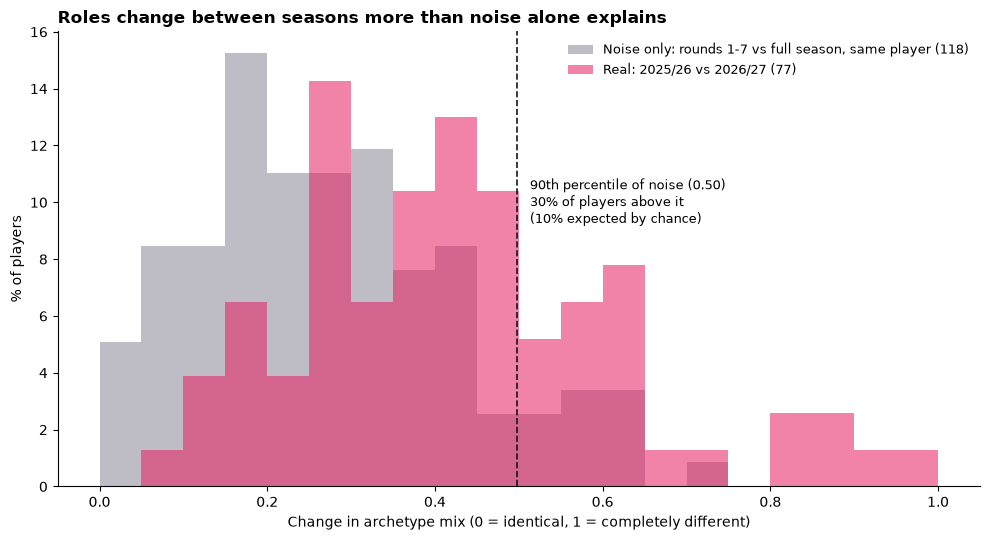

In [66]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(pair["noise_change"], bins=bins, weights=w_noise, color="#a9a6b0", alpha=0.75,
        label=f"Noise only: rounds 1-7 vs full season, same player ({len(pair)})")
ax.hist(both["role_change"], bins=bins, weights=w_real, color="#e61e63", alpha=0.55,
        label=f"Real: 2025/26 vs 2026/27 ({len(both)})")

ax.axvline(noise_p90, color="#16161a", ls="--", lw=1.2)
ax.text(noise_p90 + 0.015, ax.get_ylim()[1] * 0.68,
        f"90th percentile of noise ({noise_p90:.2f})\n{share_above:.0f}% of players above it\n(10% expected by chance)",
        fontsize=9.5, va="top")

ax.set_xlabel("Change in archetype mix (0 = identical, 1 = completely different)")
ax.set_ylabel("% of players")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Roles change between seasons more than noise alone explains", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/noise_vs_change.png", dpi=200, bbox_inches="tight")
plt.show()